# Accuracy-Efficiency Frontier

Self-contained plotting notebook for the paper frontier figure. Values are hard-coded from `RESULTS.md` plus the related-method comparison table currently in `paper/main.tex`; edit the `rows` list below when new measurements land.

In [32]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "font.size": 11,
    "axes.labelsize": 12,
    "axes.titlesize": 13,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "legend.frameon": False,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

out_dir = Path("../figs")
out_dir.mkdir(parents=True, exist_ok=True)

In [33]:
# Sources:
# - RESULTS.md, RES 320x800 table: DETR3D full baseline, naive reuse, EvoMem3D rows.
# - paper/main.tex Table 1: StreamPETR, ToC3D, SToRe3D, and EvoMem3D paper operating-point labels.
# - SEPatch3D ViT-L values were not found locally; the row below is a visible dummy placeholder.
# Keep this table intentionally boring so paper-number edits stay cheap.
rows = [
    dict(method="Full DETR3D", label="Full DETR3D", family="Full baseline", latency_ms=373.4, nds=60.80, map=51.20, marker="o"),
    ##dict(method="Naive reuse K=2", label="Reuse K=2", family="Naive reuse", latency_ms=206.7, nds=44.40, map=31.81, marker="X"),
    ##dict(method="Naive reuse K=3", label="Reuse K=3", family="Naive reuse", latency_ms=154.8, nds=36.58, map=21.48, marker="X"),
    #dict(method="StreamPETR", label="StreamPETR", family="Related", latency_ms=317, nds=61.2, map=52.10, marker="^"),
    ##dict(method="ToC3D-Fast", label="ToC3D-Fast", family="Related", latency_ms=282, nds=61.20, map=52.10, marker="^"),
    #dict(method="ToC3D-Faster", label="ToC3D-Faster", family="Related", latency_ms=239.6, nds=60.50, map=51.30, marker="^"),
    #dict(method="SEPatch3D", label="SEPatch3D (edit)", family="Related dummy", latency_ms=194.9, nds=60.30, map=51.60, marker="v"),
    dict(method="SToRe3D-1/3", label="SToRe3D 1/3", family="SToRe3D", latency_ms=285.7, nds=60.90, map=52.30, marker="^"),
    dict(method="SToRe3D-1/10", label="SToRe3D 1/10", family="SToRe3D", latency_ms=193.3, nds=60.70, map=52.10, marker="^"),
    dict(method="EvoMem3D", label="EvoMem3D", family="EvoMem3D", latency_ms=195.7, nds=60.43, map=54.01, marker="D"),
    dict(method="EvoMem3D-Fast", label="EvoMem3D-Fast", family="EvoMem3D", latency_ms=189.6, nds=60.43, map=51.37, marker="D"),
]

df = pd.DataFrame(rows)
df["fps"] = 1000.0 / df["latency_ms"]
df

,method,label,family,latency_ms,nds,map,marker,fps
0,Full DETR3D,Full DETR3D,Full baseline,373.4,60.80,51.20,o,2.678093
1,SToRe3D-1/3,SToRe3D 1/3,SToRe3D,285.7,60.90,52.30,^,3.500175
2,SToRe3D-1/10,SToRe3D 1/10,SToRe3D,193.3,60.70,52.10,^,5.173306
3,EvoMem3D,EvoMem3D,EvoMem3D,195.7,60.43,54.01,D,5.109862
4,EvoMem3D-Fast,EvoMem3D-Fast,EvoMem3D,189.6,60.43,51.37,D,5.274262


In [34]:
palette = {
    "Full baseline": "#b65b5b",
    "Naive reuse": "#8c8c8c",
    "SToRe3D": "#e6952a",
    "Related dummy": "#c6a76a",
    "EvoMem3D": "#1f7a5c",
}

sizes = {
    "Full baseline": 95,
    "Naive reuse": 80,
    "SToRe3D": 95,
    "Related dummy": 90,
    "EvoMem3D": 120,
}

# label_positions = {
#     "nds": {
#         "Full DETR3D": (356, 59.95), "Naive reuse K=2": (216, 44.25), "Naive reuse K=3": (166, 36.65),
#         "StreamPETR": (446, 59.95), "ToC3D-Fast": (391, 61.75), "ToC3D-Faster": (314, 61.65),
#         "SEPatch3D": (258, 59.25), "SToRe3D-1/3": (277, 61.65), "SToRe3D-1/10": (197, 61.45),
#         "EvoMem3D": (202, 54.35), "EvoMem3D-Fast": (154, 60.0),
#     },
#     "map": {
#         "Full DETR3D": (356, 50.55), "Naive reuse K=2": (216, 31.75), "Naive reuse K=3": (166, 21.55),
#         "StreamPETR": (446, 53.05), "ToC3D-Fast": (391, 53.25), "ToC3D-Faster": (314, 50.85),
#         "SEPatch3D": (258, 50.25), "SToRe3D-1/3": (277, 53.2), "SToRe3D-1/10": (197, 52.95),
#         "EvoMem3D": (202, 55.1), "EvoMem3D-Fast": (154, 51.1),
#     },
# }

def plot_metric(ax, metric, title, ylim):
    for family, group in df.groupby("family", sort=False):
        ax.scatter(
            group["latency_ms"],
            group[metric],
            s=sizes[family],
            c=palette[family],
            marker=group["marker"].iloc[0],
            edgecolor="white",
            linewidth=1.0,
            alpha=0.95,
            label=family,
            zorder=3,
        )

    # for _, row in df.iterrows():
    #     #text_xy = label_positions[metric][row.method]
    #     ax.annotate(
    #         row.label,
    #         (row.latency_ms, row[metric]),
    #         #xytext=text_xy,
    #         textcoords="data",
    #         ha="left" if text_xy[0] <= row.latency_ms else "right",
    #         va="center",
    #         fontsize=8.3,
    #         color="#2f2f2f",
    #         arrowprops=dict(arrowstyle="-", color="#bdbdbd", lw=0.6, shrinkA=2, shrinkB=4) if abs(text_xy[0] - row.latency_ms) > 18 or abs(text_xy[1] - row[metric]) > 1.0 else None,
    #     )

    baseline = df.loc[df.method == "Full DETR3D"].iloc[0]
    fast = df.loc[df.method == "EvoMem3D-Fast"].iloc[0]
    # ax.annotate(
    #     "",
    #     xy=(fast.latency_ms, fast[metric]),
    #     xytext=(baseline.latency_ms, baseline[metric]),
    #     arrowprops=dict(arrowstyle="-|>", lw=2.8, color="#111111", mutation_scale=18),
    #     zorder=5,
    # )
    # ax.text(
    #     280,
    #     63.05 if metric == "nds" else 55.55,
    #     "1.97x Speedup / 99.4% NDS Retained",
    #     ha="center",
    #     va="center",
    #     fontsize=9.5,
    #     fontweight="bold",
    #     color="#111111",
    #     bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9),
    #     zorder=6,
    # )

    ax.axhline(baseline[metric], color="#dddddd", lw=1.0, zorder=1)
    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel("Latency (ms/frame, lower is better)")
    ax.set_ylabel(metric.upper() if metric == "nds" else "mAP")
    ax.set_xlim(140, 470)
    ax.set_ylim(*ylim)
    ax.grid(True, color="#eeeeee", linewidth=0.8, zorder=0)
    ax.text(0.02, 0.03, "Faster", transform=ax.transAxes, fontsize=9, color="#555555")

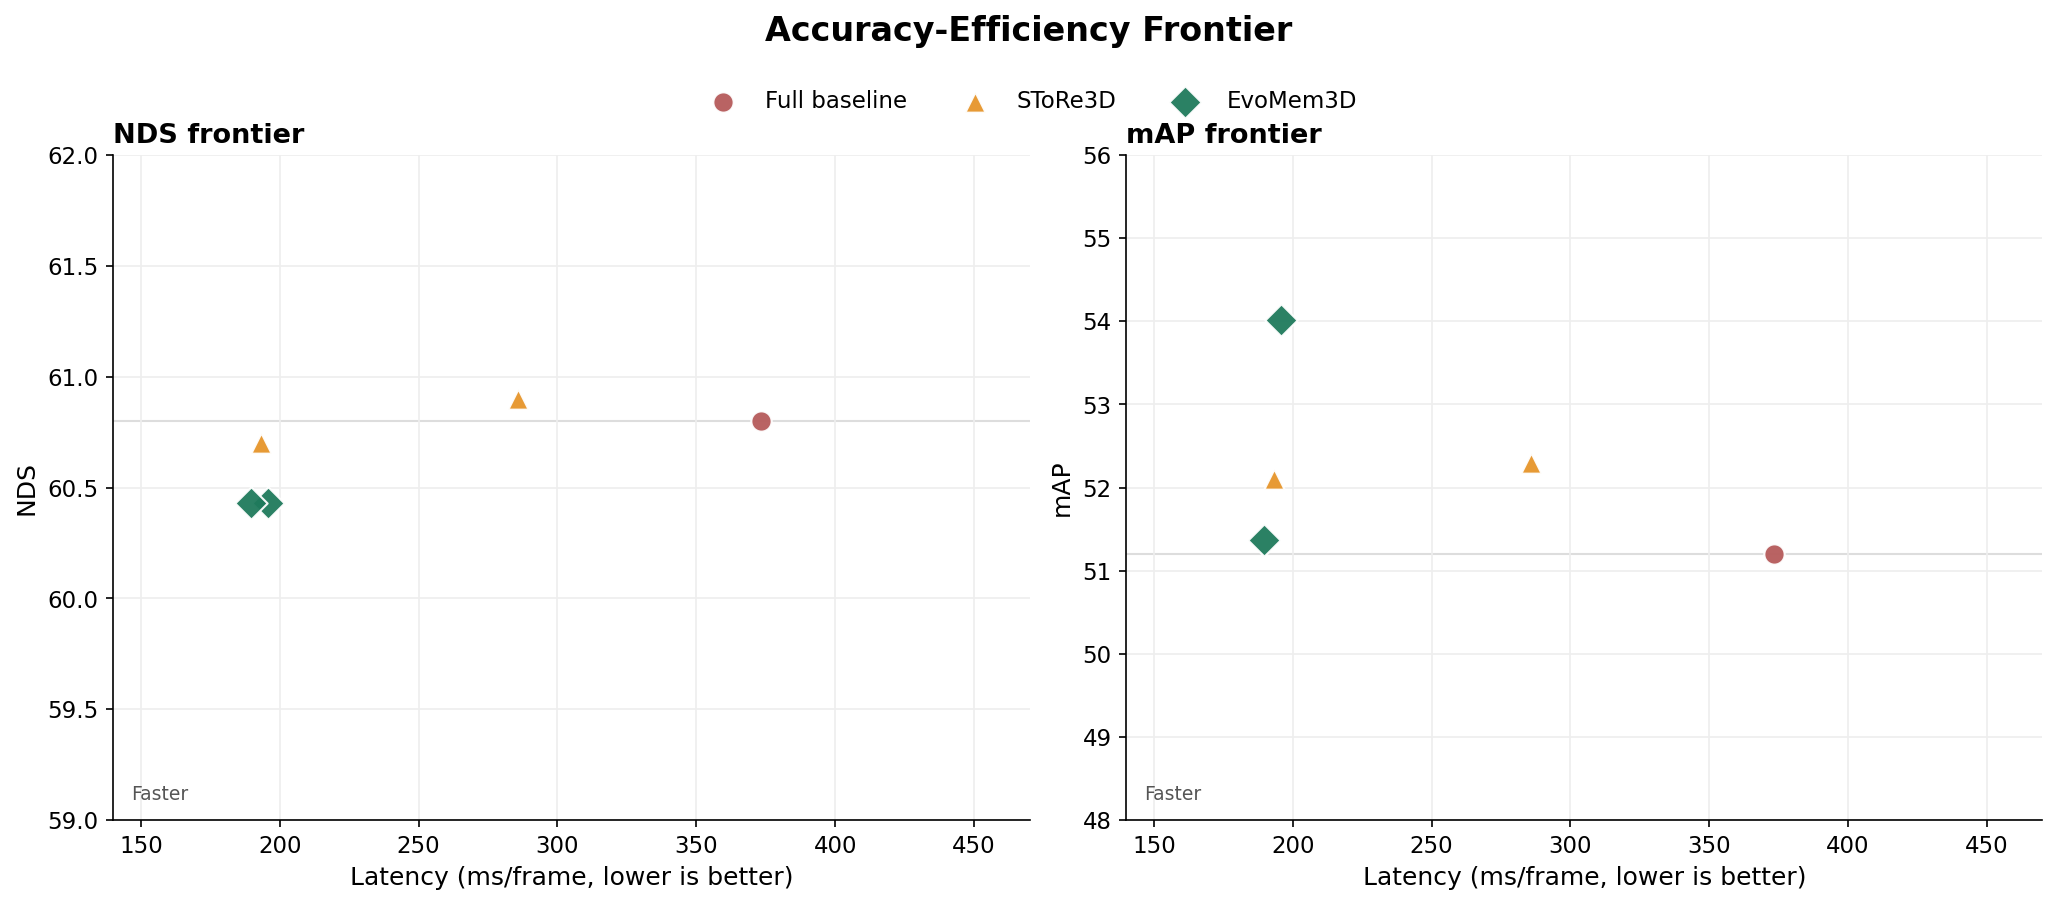

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13.6, 5.2), constrained_layout=True)

plot_metric(axes[0], "nds", "NDS frontier", (59, 62))
plot_metric(axes[1], "map", "mAP frontier", (48, 56.0))

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=4, bbox_to_anchor=(0.5, 1.06))
fig.suptitle("Accuracy-Efficiency Frontier", y=1.13, fontsize=16, fontweight="bold")

pdf_path = out_dir / "accuracy_efficiency_frontier.pdf"
png_path = out_dir / "accuracy_efficiency_frontier.png"
#fig.savefig(pdf_path, bbox_inches="tight")
#fig.savefig(png_path, bbox_inches="tight")
#print(f"Saved {pdf_path} and {png_path}")